# Pulse2BP | Predict blood pressure from a fingertip pulse

We estimate systolic (SBP) and diastolic (DBP) blood pressure from 30 seconds of fingertip PPG.
**XGBoost is our final model.** We train one XGBoost regressor for each pressure value and compare
them with Extra Trees and a simple training-median baseline.

Install the packages with `python -m pip install -r requirements.txt`. Put `Part_1.mat` through
`Part_4.mat` in the repo's `data/` folder, open this notebook, and run the cells in order.
Full preprocessing and training can take time on a CPU. [UCI dataset](https://archive.ics.uci.edu/dataset/340/cuff+less+blood+pressure+estimation)

XGBoost scored **11.60 SBP / 6.04 DBP MAE** on 12,523 test windows.

## 1. Load and prepare the pulse data

Cut the PPG and arterial blood pressure (ABP) recordings into matching windows. Screen out poor
pulse signals and filter the usable PPG. The median of the ABP high points gives us SBP. The
median of the low points gives us DBP. The models learn from the PPG measurements.

In [ ]:
# Set up paths and load the libraries.

import csv
import os
import shutil
import tempfile
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from itertools import combinations
from pathlib import Path
from zipfile import ZipFile

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from numpy.lib.stride_tricks import sliding_window_view
from scipy.fft import rfft, rfftfreq
from scipy.signal import butter, filtfilt, find_peaks, welch, windows
from sklearn.model_selection import train_test_split
from threadpoolctl import threadpool_limits

default_data = Path("../data") if Path.cwd().name == "notebooks" else Path("data")
data_dir = Path(os.environ.get("PULSE2BP_RAW_DIR", default_data))
csv_paths = {
    5: Path(os.environ.get("PULSE2BP_FEATURE_CSV", default_data / "bp_training_dataset_5s.csv")),
    30: Path(os.environ.get("PULSE2BP_30S_CSV", default_data / "bp_training_dataset_30s.csv")),
}
archive_path = os.environ.get("PULSE2BP_30S_WAVEFORM_NPZ")
record_limit = os.environ.get("PULSE2BP_SMOKE_RECORDS_PER_PART")
if record_limit:
    csv_paths = {size: path.with_name(f"{path.stem}_smoke.csv") for size, path in csv_paths.items()}
threads = int(os.environ.get("PULSE2BP_THREADS", "6"))


In [ ]:
# Define features that describe the pulse waveform.

WAVE_FEATURES = [
    *(f"ppg_q{q}" for q in (5, 25, 50, 75, 95)),
    "slope_q05",
    "slope_q95",
    "slope_rms",
    "curvature_rms",
    "spectral_centroid",
    "spectral_entropy",
    "pulse_repetition",
    "half_cycle_similarity",
    *(f"harmonic_{h}_power" for h in range(1, 6)),
    "spectral_heart_rate",
    "pulse_positive_fraction",
    "slope_positive_fraction",
]


WINDOW_KEY = ["file", "record_index", "start_sample"]


def waveform_features(ppg):
    """Summarize cleaned 125 Hz PPG without using BP labels or recording IDs."""
    ppg = np.asarray(ppg, dtype=np.float32)
    count, width = ppg.shape
    centered = ppg - ppg.mean(axis=1, keepdims=True)
    normalized = centered / np.maximum(centered.std(axis=1, keepdims=True), 1e-8)
    slope = np.diff(normalized, axis=1)
    curvature = np.diff(slope, axis=1)
    quantiles = np.percentile(ppg, [5, 25, 50, 75, 95], axis=1).T
    slope_tails = np.percentile(slope, [5, 95], axis=1).T
    nfft = 1 << (width - 1).bit_length()
    freq = rfftfreq(nfft, 1 / 125)
    signal_power = np.abs(rfft(normalized * windows.hann(width).astype(np.float32), n=nfft)) ** 2
    use = (freq >= 0.45) & (freq <= 10)
    freq, power = freq[use], signal_power[:, use]
    fractions = power / np.maximum(power.sum(axis=1, keepdims=True), 1e-8)
    hr_bins = (freq >= 0.5) & (freq <= 3.3)
    hz = freq[hr_bins][np.argmax(power[:, hr_bins], axis=1)]
    period = np.rint(125 / hz).astype(int)
    indices = np.arange(width - 250)
    repetition = (
        normalized[:, indices] * normalized[np.arange(count)[:, None], indices + period[:, None]]
    ).mean(axis=1)
    half = (
        normalized[:, indices]
        * normalized[np.arange(count)[:, None], indices + (period // 2)[:, None]]
    ).mean(axis=1)
    harmonics = [
        np.sum(fractions * (np.abs(freq[None, :] - hz[:, None] * h) <= 0.30), axis=1)
        for h in range(1, 6)
    ]
    return np.column_stack(
        [
            quantiles,
            slope_tails,
            np.sqrt((slope**2).mean(axis=1)),
            np.sqrt((curvature**2).mean(axis=1)),
            fractions @ freq,
            -np.sum(fractions * np.log(np.maximum(fractions, 1e-12)), axis=1),
            repetition,
            half,
            *harmonics,
            hz * 60,
            (normalized > 0).mean(axis=1),
            (slope > 0).mean(axis=1),
        ]
    ).astype(np.float32)


def add_waveform_features(frame, archive_path, seconds):
    """Read the waveform matrix in batches so it does not need to fit in RAM."""
    with np.load(archive_path, allow_pickle=False) as data:
        metadata = pd.DataFrame(
            {
                "file": data["file_names"][data["file_index"]],
                "record_index": data["record_index"],
                "start_sample": data["start_sample"],
            }
        )
        pressures = data["y"]
    alignment = pd.MultiIndex.from_frame(metadata).get_indexer(
        pd.MultiIndex.from_frame(frame[WINDOW_KEY])
    )
    if np.any(alignment < 0):
        raise ValueError("The waveform archive does not have all feature CSV rows.")
    np.testing.assert_allclose(pressures[alignment], frame[["sbp", "dbp"]], rtol=1e-7, atol=1e-8)
    result = np.empty((len(metadata), len(WAVE_FEATURES)), dtype=np.float32)
    with ZipFile(archive_path) as archive, archive.open("X.npy") as stream:
        version = np.lib.format.read_magic(stream)
        if version != (1, 0):
            raise ValueError(f"Unsupported NPY header {version}")
        (rows, width), fortran, dtype = np.lib.format.read_array_header_1_0(stream)
        if (
            rows != len(metadata)
            or width != seconds * 125
            or fortran
            or dtype != np.dtype("float32")
        ):
            raise ValueError("Unexpected waveform archive layout or duration.")
        for start in range(0, rows, 1024):
            batch = min(1024, rows - start)
            x = np.frombuffer(stream.read(batch * width * dtype.itemsize), dtype=dtype).reshape(
                batch, width
            )
            result[start : start + batch] = waveform_features(x)
    if not np.isfinite(result).all():
        raise ValueError("Non-finite waveform feature detected.")
    return frame.assign(**dict(zip(WAVE_FEATURES, result[alignment].T)))


In [ ]:
# Measure pulse shape and summarize earlier windows.

BEAT_NAMES = [
    *(f"beat_shape_{j:02d}" for j in range(1, 24)),
    *(f"beat_variation_{j:02d}" for j in range(2, 24, 3)),
    "usable_beat_count",
    "beat_duration_iqr",
    "beat_amplitude_iqr",
    "beat_rise_fraction_median",
    "beat_rise_fraction_iqr",
    "beat_area_median",
    "beat_area_iqr",
    "late_pulse_curvature",
    "peak_contrast",
]


PHASE = np.linspace(0, 1, 25)


def beat_template(ppg):
    """Put each pulse on the same time and amplitude scales, then summarize its shape."""
    peaks, _ = find_peaks(ppg, distance=41, prominence=0.3 * np.std(ppg))
    if len(peaks) < 3:
        return np.zeros(len(BEAT_NAMES), dtype=np.float32)
    feet = np.array([lo + np.argmin(ppg[lo:hi]) for lo, hi in zip(peaks[:-1], peaks[1:])])
    start, end, peak = feet[:-1], feet[1:], peaks[1:-1]
    duration = end - start
    height = ppg[peak] - ppg[start]
    valid = (duration >= 41) & (duration <= 250) & (height > 0.01) & (start < peak) & (peak < end)
    if not valid.any():
        return np.zeros(len(BEAT_NAMES), dtype=np.float32)
    start, end, peak, duration, height = (x[valid] for x in (start, end, peak, duration, height))
    offset = duration[:, None] * PHASE
    idx = np.floor(offset).astype(int)
    weights = offset - idx
    lo = start[:, None] + idx
    hi = np.minimum(lo + 1, end[:, None])
    samples = ppg[lo] * (1 - weights) + ppg[hi] * weights
    floor = ppg[start, None] + (ppg[end, None] - ppg[start, None]) * PHASE
    pulse = (samples - floor) / height[:, None]
    q25, median, q75 = np.percentile(pulse, [25, 50, 75], axis=0)
    area = pulse.mean(axis=1)
    rise = (peak - start) / duration

    def iqr(values):
        a, b = np.percentile(values, [25, 75])
        return b - a

    return np.array(
        [
            *median[1:24],
            *(q75 - q25)[2:24:3],
            len(pulse),
            iqr(duration) / 125,
            iqr(height),
            np.median(rise),
            iqr(rise),
            np.median(area),
            iqr(area),
            np.abs(np.diff(median, n=2)[11:]).mean(),
            median.max() - median[18],
        ],
        dtype=np.float32,
    )


def add_beat_templates(frame, archive_path, duration):
    """Join the original waveform to its feature row using its source ID."""
    key = ["file", "record_index", "start_sample"]
    with np.load(archive_path, allow_pickle=False) as archive:
        source = pd.DataFrame(
            {
                "file": archive["file_names"][archive["file_index"]],
                "record_index": archive["record_index"],
                "start_sample": archive["start_sample"],
            }
        )
        labels = archive["y"]
    order = pd.MultiIndex.from_frame(source).get_indexer(pd.MultiIndex.from_frame(frame[key]))
    if (order < 0).any():
        raise ValueError("Feature windows and waveform archive do not match.")
    np.testing.assert_allclose(labels[order], frame[["sbp", "dbp"]], rtol=1e-7, atol=1e-8)
    data = np.empty((len(source), len(BEAT_NAMES)), dtype=np.float32)
    with ZipFile(archive_path) as archive, archive.open("X.npy") as stream:
        assert np.lib.format.read_magic(stream) == (1, 0)
        (rows, width), fortran, dtype = np.lib.format.read_array_header_1_0(stream)
        assert (
            rows == len(source)
            and width == duration * 125
            and not fortran
            and dtype == np.dtype("float32")
        )
        for start in range(0, rows, 512):
            batch = min(512, rows - start)
            x = np.frombuffer(stream.read(batch * width * dtype.itemsize), dtype=dtype).reshape(
                batch, width
            )
            data[start : start + batch] = [beat_template(pulse) for pulse in x]
            if start % 16384 == 0:
                print(f"Beat templates: {start + batch:,} / {rows:,}", flush=True)
    assert np.isfinite(data).all()
    return frame.assign(**dict(zip(BEAT_NAMES, data[order].T)))


def add_template_history(frame, base, beats):
    """Summarize up to eight usable windows, without reading future windows."""
    frame = frame.sort_values(["file", "record_index", "start_sample"], kind="stable").reset_index(
        drop=True
    )
    columns = [*base, *beats[2:23:3], *beats[-9:]]
    grouped = frame.groupby(["file", "record_index"], sort=False)[columns]
    history = grouped.rolling(8, min_periods=1).median().reset_index(level=[0, 1], drop=True)
    history = history.add_prefix("history8_")
    return frame.join(history), list(history.columns)


In [ ]:
# Read the MATLAB files and write labeled feature rows.

FEATURES = [
    "heart_rate_bpm",
    "beat_interval_std_ms",
    "pulse_height",
    "rise_time_s",
    "fall_time_s",
    "rise_fall_ratio",
    "pulse_width_s",
    "max_upslope",
    "ppg_std",
    "ppg_min",
    "ppg_max",
    "ppg_range",
    "ppg_skewness",
    "ppg_kurtosis",
]


TARGETS = ["sbp", "dbp"]


SOURCE = ["file", "record_index", "start_sample"]


SEED = 42


FS = 125


BAND = (0.5, 8)


MIN_PEAK_DISTANCE = int(FS * 60 / 180)


MIN_COMPLETE_BEATS = 2


FILTER_B, FILTER_A = butter(4, BAND, btype="band", fs=FS)


COLUMNS = [*SOURCE, "inband_power_ratio", *TARGETS, *FEATURES, "n_beats"]


def inband_power_ratio(ppg):
    """Measure the share of signal power in the pulse band."""
    frequencies, power = welch(ppg, fs=FS, nperseg=256, axis=-1)
    band = (frequencies >= BAND[0]) & (frequencies <= BAND[1])
    total = power.sum(axis=-1)
    return np.divide(
        power[..., band].sum(axis=-1),
        total,
        out=np.full_like(total, np.nan, dtype=float),
        where=total > 0,
    )


def pressure_label(abp):
    """Estimate SBP and DBP from the median ABP peaks and troughs."""
    peaks, _ = find_peaks(abp, distance=MIN_PEAK_DISTANCE)
    troughs, _ = find_peaks(-abp, distance=MIN_PEAK_DISTANCE)
    if min(len(peaks), len(troughs)) < 3:
        return None
    sbp, dbp = np.median(abp[peaks]), np.median(abp[troughs])
    return (sbp, dbp) if sbp > dbp else None


def extract_features(ppg):
    """Use the pulse measurements from ppg_feature_extraction.ipynb."""
    ppg = np.asarray(ppg, dtype=float)
    spread = np.std(ppg)
    if spread == 0:
        return None
    peaks, _ = find_peaks(ppg, distance=MIN_PEAK_DISTANCE, prominence=0.3 * spread)
    rise, fall, height, width, upslope = [], [], [], [], []
    for previous, peak, following in zip(peaks, peaks[1:], peaks[2:]):
        foot = previous + np.argmin(ppg[previous:peak])
        next_foot = peak + np.argmin(ppg[peak:following])
        if not foot < peak < next_foot:
            continue
        h = ppg[peak] - ppg[foot]
        rise.append((peak - foot) / FS)
        fall.append((next_foot - peak) / FS)
        height.append(h)
        width.append(np.sum(ppg[foot : next_foot + 1] >= ppg[foot] + 0.5 * h) / FS)
        upslope.append(np.max(np.diff(ppg[foot : peak + 1])) * FS)
    if len(rise) < MIN_COMPLETE_BEATS:
        return None
    intervals = np.diff(peaks) / FS
    standardized = (ppg - np.mean(ppg)) / spread
    values = (
        60 / np.mean(intervals),
        np.std(intervals) * 1000,
        np.mean(height),
        np.mean(rise),
        np.mean(fall),
        np.mean(np.asarray(rise) / fall),
        np.mean(width),
        np.mean(upslope),
        spread,
        np.min(ppg),
        np.max(ppg),
        np.ptp(ppg),
        np.mean(standardized**3),
        np.mean(standardized**4) - 3,
        len(rise),
    )
    return values if np.isfinite(values).all() else None


def process_part(task):
    """Extract labeled feature rows from one MATLAB file."""
    path, destination, seconds, record_limit, include_waveform = task
    width = seconds * FS
    candidates = accepted = rows = 0
    with h5py.File(path, "r") as source, destination.open("w", encoding="utf-8", newline="") as out:
        writer = csv.writer(out)
        for record_id, ref in enumerate(source[path.stem][:record_limit, 0]):
            record = source[ref][:]
            if record.shape[1] != 3:
                record = record.T
            if record.shape[1] != 3:
                raise ValueError(f"Unexpected signal shape {record.shape} in {path}")
            count = len(record) // width
            candidates += count
            if count == 0:
                continue
            ppg, abp = record[: count * width, :2].T.reshape(2, count, width)
            ratio = inband_power_ratio(ppg)
            keep = (
                np.isfinite(ppg).all(axis=1)
                & np.isfinite(abp).all(axis=1)
                & (np.std(ppg, axis=1) >= 1e-3)
                & (ratio >= 0.6)
            )
            offsets, labels = [], []
            for idx in np.flatnonzero(keep):
                label = pressure_label(abp[idx])
                if label is not None:
                    offsets.append(idx)
                    labels.append(label)
            if not offsets:
                continue
            accepted += len(offsets)
            cleaned = filtfilt(FILTER_B, FILTER_A, ppg[offsets], axis=-1).astype(np.float32)
            extra = waveform_features(cleaned) if include_waveform else [()] * len(cleaned)
            if include_waveform and seconds == 30:
                extra = np.column_stack([extra, [beat_template(pulse) for pulse in cleaned]])
            for idx, label, signal, waveform in zip(offsets, labels, cleaned, extra):
                features = extract_features(signal)
                if features is not None:
                    writer.writerow(
                        (
                            path.name,
                            record_id,
                            idx * width,
                            np.float32(ratio[idx]),
                            *label,
                            *features,
                            *waveform,
                        )
                    )
                    rows += 1
    print(
        f"{path.name}: {candidates:,} candidate windows, {accepted:,} cleaned, {rows:,} feature rows",
        flush=True,
    )
    return rows


def prepare(data_dir, output, seconds, record_limit, include_waveform=False):
    """Build the feature CSV from the four dataset files."""
    paths = [data_dir / f"Part_{i}.mat" for i in range(1, 5)]
    for path in paths:
        if not path.is_file():
            raise FileNotFoundError(
                f"Put all four UCI Part_*.mat files in {data_dir}. Missing {path.name}."
            )
    output.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.TemporaryDirectory(prefix="pulse2bp_", dir=output.parent) as scratch:
        scratch = Path(scratch)
        parts = [scratch / f"{p.stem}.csv" for p in paths]
        with ThreadPoolExecutor(max_workers=4) as pool:
            rows = sum(
                pool.map(
                    process_part,
                    [(p, d, seconds, record_limit, include_waveform) for p, d in zip(paths, parts)],
                )
            )
        if not rows:
            raise ValueError("No windows passed preprocessing and feature extraction.")
        staged = scratch / output.name
        with staged.open("wb") as out:
            columns = COLUMNS + (WAVE_FEATURES if include_waveform else [])
            if include_waveform and seconds == 30:
                columns += BEAT_NAMES
            out.write((",".join(columns) + "\r\n").encode("utf-8"))
            for part in parts:
                with part.open("rb") as source:
                    shutil.copyfileobj(source, out)
        staged.replace(output)
    print(f"Saved {rows:,} feature rows to {output}")


def load_features(path):
    """Load and validate the feature table."""
    data = pd.read_csv(path, usecols=[*SOURCE, *FEATURES, *TARGETS])
    if data.empty or data[SOURCE].isna().any().any() or data.duplicated(SOURCE).any():
        raise ValueError(f"Missing or repeated window IDs in {path}")
    if (
        not np.isfinite(data[FEATURES + TARGETS].to_numpy()).all()
        or not (data.sbp > data.dbp).all()
    ):
        raise ValueError(f"Invalid features or pressure labels in {path}")
    return data


In [ ]:
# Build or reuse the feature tables.

for seconds, path in csv_paths.items():
    if not path.is_file():
        prepare(
            data_dir,
            path,
            seconds,
            int(record_limit) if record_limit else None,
            include_waveform=(seconds == 30),
        )
reference_features = load_features(csv_paths[5])
thirty_features = load_features(csv_paths[30])
print(f"{len(thirty_features):,} usable 30-second windows before the split checks.")


## 2. Split recordings and build model inputs

Keep every recording in one set. We use the five-second feature table to reproduce the original
recording assignments. The models below train and test on 30-second windows only. Training
teaches the model, validation chooses settings, and test measures the error.

In [ ]:
# Group recordings and check for duplicate inputs.


def split_recordings(datasets):
    """Link recordings with matching model inputs before splitting them."""
    groups = {size: list(zip(data.file, data.record_index)) for size, data in datasets.items()}
    parents = {g: g for items in groups.values() for g in items}

    def root(group):
        while parents[group] != group:
            parents[group] = parents[parents[group]]
            group = parents[group]
        return group

    fingerprints = {}
    for size, data in datasets.items():
        fingerprints[size] = pd.util.hash_pandas_object(
            data[FEATURES].astype("float32"), index=False
        )
        first_seen = {}
        for fingerprint, group in zip(fingerprints[size], groups[size]):
            first = first_seen.setdefault(fingerprint, group)
            a, b = sorted((root(group), root(first)))
            parents[b] = a

    # A reference split by recording alone shows how many fingerprints would cross splits.
    def assignments(keys):
        train, held_out = train_test_split(sorted(keys), test_size=0.30, random_state=SEED)
        val, test = train_test_split(held_out, test_size=0.50, random_state=SEED + 1)
        return {
            key: label
            for label, items in [("train", train), ("validation", val), ("test", test)]
            for key in items
        }

    initial = assignments(parents)
    components = {g: root(g) for g in parents}
    final = assignments(set(components.values()))
    frames, audit = {}, []
    for size, data in datasets.items():
        frame = data.assign(split=[final[components[g]] for g in groups[size]])
        checks = pd.DataFrame(
            {
                "fingerprint": fingerprints[size],
                "after": frame.split,
                "before": [initial[g] for g in groups[size]],
            }
        )
        overlaps = checks.groupby("fingerprint")[["before", "after"]].nunique().gt(1).sum()
        assert (
            overlaps["after"] == 0
            and frame.groupby(["file", "record_index"]).split.nunique().max() == 1
        )
        if set(frame.split) != {"train", "validation", "test"}:
            raise ValueError(
                "Each duration needs enough independent recordings for all three splits."
            )
        frames[size] = frame
        audit.append(
            {
                "seconds": size,
                "recordings": len(set(groups[size])),
                "duplicate inputs before": overlaps["before"],
                "duplicate inputs after": overlaps["after"],
                **Counter(frame.split),
            }
        )
    return frames, pd.DataFrame(audit).set_index("seconds")


def same_recordings(frame, reference):
    """Apply the existing recording split to another window length."""
    lookup = reference[["file", "record_index", "split"]].drop_duplicates()
    frame = frame.merge(lookup, on=["file", "record_index"], how="left", validate="many_to_one")
    if frame.split.isna().any():
        raise ValueError("A recording is missing from the original split.")
    # Keep all test rows. Remove exact overlaps from the fitting side only.
    hashes = pd.util.hash_pandas_object(frame[FEATURES].astype("float32"), index=False)
    test_hashes = hashes.loc[frame.split == "test"]
    val_hashes = hashes.loc[frame.split == "validation"]
    discard = ((frame.split != "test") & hashes.isin(test_hashes)) | (
        (frame.split == "train") & hashes.isin(val_hashes)
    )
    print(
        f"Dropped {int(discard.sum())} fitting/validation rows that duplicate a later split.",
        flush=True,
    )
    return frame.loc[~discard]


def check_inputs(frame, columns):
    """Check for repeated model inputs across data splits."""
    assert np.isfinite(frame[columns].to_numpy()).all()
    hashes = pd.util.hash_pandas_object(frame[columns].astype("float32"), index=False)
    spread = frame.assign(fingerprint=hashes).groupby("fingerprint").split.nunique()
    if (spread > 1).any():
        raise ValueError("Exact model inputs cross the holdout split.")


def add_ppg_history(frame, columns):
    """Use the current and up to three preceding windows from the same recording."""
    frame = frame.sort_values(["file", "record_index", "start_sample"], kind="stable")
    group = frame.groupby(["file", "record_index"], sort=False)[columns]
    # Keep rows aligned when attaching the rolling medians to the current window.
    history = group.rolling(4, min_periods=1).median().reset_index(level=[0, 1], drop=True)
    levels = history.add_prefix("trailing_")
    changes = (frame[columns] - history).add_prefix("delta_")
    frame = frame.join(levels).join(changes)
    return frame, [*levels.columns, *changes.columns]


In [ ]:
# Apply the recording split to the 30-second data.

reference_splits, _ = split_recordings({5: reference_features})
frame = same_recordings(thirty_features, reference_splits[5]).reset_index(drop=True)
frame, recent = add_ppg_history(frame, FEATURES)
display(frame.split.value_counts().reindex(["train", "validation", "test"]).to_frame("Windows"))


,Windows
split,
train,58056
validation,12840
test,12523


In [ ]:
# Add raw optical measurements from each PPG window.


def raw_window_features(x):
    """Measure optical level, amplitude, and frequency content."""
    quantile = np.percentile(x, [5, 25, 50, 75, 95], axis=1)
    q05, q25, center, q75, q95 = quantile
    span = q95 - q05
    block = x.reshape(len(x), 6, 625)
    block_center = np.median(block, axis=2)
    block_std = block.std(axis=2)
    freq, power = welch(x, fs=125, nperseg=1250, axis=1)
    total = power[:, freq > 0].sum(axis=1)
    relative = lambda v, d: v / np.maximum(d, 1e-6)
    bands = [(0.1, 0.3), (0.3, 0.5), (0.5, 1), (1, 2), (2, 4), (4, 8), (8, 16)]
    result = {
        "optical_level": center,
        "optical_q05": q05,
        "optical_q95": q95,
        "optical_ac_dc": relative(span, np.abs(center)),
        "optical_iqr_dc": relative(q75 - q25, np.abs(center)),
        "optical_block_drift": relative(np.ptp(block_center, axis=1), span),
        "optical_block_ac_variation": relative(block_std.std(axis=1), block_std.mean(axis=1)),
        "optical_ac": span,
        "optical_median_to_low": relative(center - q05, span),
    }
    for i, (lo, hi) in enumerate(bands):
        result[f"optical_band_{i}"] = relative(
            power[:, (freq >= lo) & (freq < hi)].sum(axis=1), total
        )
    return pd.DataFrame(result, dtype=np.float32)


def add_raw_features(frame, raw_dir):
    """Match raw optical measurements to the existing windows."""
    frame = frame.reset_index(drop=True)
    chunks = []
    for file, part in frame.groupby("file", sort=False):
        path = raw_dir / file
        with h5py.File(path, "r") as f:
            refs = f[path.stem]
            for ri, group in part.groupby("record_index", sort=False):
                rec = f[refs[ri, 0]]
                signal = rec[:, 0] if rec.shape[1] == 3 else rec[0, :]
                x = signal[group.start_sample.to_numpy()[:, None] + np.arange(3750)]
                result = raw_window_features(x)
                result.index = group.index
                chunks.append(result)
        print(f"{file}: raw PPG features extracted for {len(part):,} windows", flush=True)
    features = pd.concat(chunks).sort_index()
    assert features.index.equals(frame.index) and np.isfinite(features.to_numpy()).all()
    return pd.concat([frame, features], axis=1), list(features.columns)


In [ ]:
# Load clean waveforms and measure short patterns.


def waveform_matrix(frame, archive_path):
    """Read aligned cleaned PPG and decimate to 31.25 Hz after the existing 8 Hz low-pass."""
    key = ["file", "record_index", "start_sample"]
    with np.load(archive_path, allow_pickle=False) as archive:
        source = pd.DataFrame(
            {
                "file": archive["file_names"][archive["file_index"]],
                "record_index": archive["record_index"],
                "start_sample": archive["start_sample"],
            }
        )
        labels = archive["y"]
    order = pd.MultiIndex.from_frame(source).get_indexer(pd.MultiIndex.from_frame(frame[key]))
    if (order < 0).any():
        raise ValueError("Feature windows and waveform archive do not match.")
    np.testing.assert_allclose(labels[order], frame[["sbp", "dbp"]], rtol=1e-7, atol=1e-8)
    with ZipFile(archive_path) as archive, archive.open("X.npy") as stream:
        if np.lib.format.read_magic(stream) != (1, 0):
            raise ValueError("Unexpected waveform archive format.")
        (rows, width), fortran, dtype = np.lib.format.read_array_header_1_0(stream)
        if rows != len(source) or width != 3750 or fortran or dtype != np.dtype("float32"):
            raise ValueError("Expected 30-second float32 PPG waveforms.")
        data = np.empty((rows, (width + 3) // 4), dtype=np.float32)
        for start in range(0, rows, 1024):
            batch = min(1024, rows - start)
            wave = np.frombuffer(stream.read(batch * width * dtype.itemsize), dtype=dtype).reshape(
                batch, width
            )
            data[start : start + batch] = wave[:, ::4]
    return normalize_waveforms(data[order])


def normalize_waveforms(data):
    """Center and scale each waveform before it enters the CNN."""
    data -= data.mean(axis=1, keepdims=True)
    data /= np.maximum(data.std(axis=1, keepdims=True), 1e-6)
    return data.clip(-10, 10)


def waveform_matrix_from_mat(frame, data_dir, filter_b, filter_a):
    """Rebuild the same CNN input from the original files when no NPZ is available."""
    import h5py
    from scipy.signal import filtfilt

    width = 3750
    data = np.empty((len(frame), (width + 3) // 4), dtype=np.float32)
    for filename, part in frame.reset_index(drop=True).groupby("file", sort=False):
        path = data_dir / filename
        with h5py.File(path, "r") as raw:
            refs = raw[path.stem]
            for record_index, group in part.groupby("record_index", sort=False):
                record = raw[refs[record_index, 0]][:]
                ppg = record[:, 0] if record.shape[1] == 3 else record[0]
                windows = ppg[group.start_sample.to_numpy()[:, None] + np.arange(width)]
                data[group.index] = filtfilt(filter_b, filter_a, windows, axis=1).astype(
                    np.float32
                )[:, ::4]
    return normalize_waveforms(data)


def multiscale_patterns(frame, wave):
    """Count short waveform patterns at several time scales."""
    positions = list(combinations(range(9), 3))
    seed = np.random.default_rng(42)
    selected = sorted(seed.choice(len(positions), 24, replace=False))
    kernel = np.full((24, 9), -1, dtype=np.float32)
    for i, j in enumerate(selected):
        kernel[i, list(positions[j])] = 2
    kernel /= np.linalg.norm(kernel, axis=1, keepdims=True)
    result = np.empty((len(frame), 144), dtype=np.float32)
    with threadpool_limits(limits=2):
        for start in range(0, len(frame), 384):
            x = wave[start : start + 384]
            for d in (2, 4, 8):
                patches = sliding_window_view(x, 1 + 8 * d, axis=1)[:, ::4, ::d]
                response = np.ascontiguousarray(patches) @ kernel.T
                lo = (d.bit_length() - 2) * 48
                result[start : start + len(x), lo : lo + 24] = (response > 0).mean(axis=1)
                result[start : start + len(x), lo + 24 : lo + 48] = np.maximum(response, 0).mean(
                    axis=1
                )
            if start % 19200 == 0:
                print(f"Waveform pattern features: {start + len(x):,}/{len(frame):,}", flush=True)
    assert np.isfinite(result).all()
    columns = [f"pattern_{i:03d}" for i in range(result.shape[1])]
    return pd.concat(
        [frame, pd.DataFrame(result, index=frame.index, columns=columns)], axis=1
    ), columns


In [ ]:
# Match pulse features to the windows, then build the model input table.

cached_columns = pd.read_csv(csv_paths[30], nrows=0).columns
if set(WAVE_FEATURES + BEAT_NAMES).issubset(cached_columns):
    shapes = pd.read_csv(csv_paths[30], usecols=[*WINDOW_KEY, *WAVE_FEATURES, *BEAT_NAMES])
    frame = frame.merge(shapes, on=WINDOW_KEY, how="left", validate="one_to_one")
elif archive_path:
    frame = add_waveform_features(frame, Path(archive_path), 30)
    frame = add_beat_templates(frame, Path(archive_path), 30)
else:
    raise ValueError(
        "Provide the matching waveform archive or regenerate the 30-second feature CSV."
    )

frame, history = add_template_history(frame, FEATURES, BEAT_NAMES)
frame, optical = add_raw_features(frame, data_dir)
if archive_path:
    wave = waveform_matrix(frame, Path(archive_path))
else:
    wave = waveform_matrix_from_mat(frame, data_dir, FILTER_B, FILTER_A)
frame, patterns = multiscale_patterns(frame, wave)
feature_names = [*FEATURES, *WAVE_FEATURES, *BEAT_NAMES, *optical, *recent, *history, *patterns]
check_inputs(frame, feature_names)
del wave


## 3. Train XGBoost and compare it with Extra Trees

The baseline always predicts the median BP from training. Extra Trees and XGBoost both learn
from the pulse measurements. Validation picks the number of XGBoost trees and whether to
smooth each model's predictions using its own earlier predictions from the same recording.
Each model produces its own BP estimates.

In [ ]:
# Set how much to smooth each model's predictions using validation.


def causal_smooth(frame, prediction, half_life_seconds):
    """Smooth within each recording using real elapsed time and no future predictions."""
    if half_life_seconds == 0:
        return prediction.copy()
    keys = list(zip(frame.file, frame.record_index))
    times = frame.start_sample.to_numpy() / 125
    smoothed = prediction.copy()
    for i in range(1, len(frame)):
        if keys[i] == keys[i - 1]:
            dt = times[i] - times[i - 1]
            assert dt > 0
            weight = 2 ** (-dt / half_life_seconds)
            smoothed[i] = weight * smoothed[i - 1] + (1 - weight) * prediction[i]
    return smoothed


def choose_smoothing(frame, pred_val, pred_test):
    """Choose the amount of smoothing using validation MAE."""
    val, test = (frame.loc[frame.split == split] for split in ("validation", "test"))
    yv, yt = val[["sbp", "dbp"]].to_numpy(), test[["sbp", "dbp"]].to_numpy()
    times = [0, 15, 30, 60, 120, 240]
    candidates = [causal_smooth(val, pred_val, t) for t in times]
    choice = np.argmin([np.abs(yv - p).mean(axis=0) for p in candidates], axis=0)
    v = np.column_stack([candidates[j][:, k] for k, j in enumerate(choice)])
    t = np.column_stack(
        [causal_smooth(test, pred_test, times[j])[:, k] for k, j in enumerate(choice)]
    )
    return v, t, [times[j] for j in choice]


In [ ]:
# Fit the models and calculate the error for each pressure value.

import numpy as np
import pandas as pd
from sklearn.ensemble import ExtraTreesRegressor
from xgboost import XGBRegressor

TARGETS = ["sbp", "dbp"]


def train_and_score(frame, feature_names, threads=6):
    """Train both regressors and compare them with the training median."""
    train, validation, test = [
        frame.loc[frame.split.eq(split)] for split in ("train", "validation", "test")
    ]
    x_train, x_val, x_test = [
        part[feature_names].to_numpy(dtype=np.float32) for part in (train, validation, test)
    ]
    y_train, y_val, y_test = [part[TARGETS].to_numpy() for part in (train, validation, test)]

    xgboost = []
    for i, target in enumerate(TARGETS):
        model = XGBRegressor(
            objective="reg:squarederror",
            n_estimators=1350,
            max_depth=9,
            learning_rate=0.055,
            min_child_weight=6,
            subsample=0.85,
            colsample_bytree=0.85,
            reg_lambda=2,
            tree_method="hist",
            max_bin=128,
            eval_metric="mae",
            early_stopping_rounds=45,
            n_jobs=threads,
            random_state=42,
        )
        model.fit(x_train, y_train[:, i], eval_set=[(x_val, y_val[:, i])], verbose=250)
        xgboost.append(model)
        print(f"{target.upper()} XGBoost trained with {model.best_iteration + 1} trees.")

    print("Training Extra Trees for the comparison.")
    extra_trees = ExtraTreesRegressor(
        n_estimators=120,
        max_depth=18,
        min_samples_leaf=4,
        max_features=0.5,
        n_jobs=threads,
        random_state=42,
    ).fit(x_train, y_train)
    median = np.median(y_train, axis=0)

    predictions = {
        "Training median": (
            np.broadcast_to(median, y_val.shape),
            np.broadcast_to(median, y_test.shape),
        ),
        "Extra Trees": (extra_trees.predict(x_val), extra_trees.predict(x_test)),
        "XGBoost": tuple(
            np.column_stack([model.predict(inputs) for model in xgboost])
            for inputs in (x_val, x_test)
        ),
    }
    # Each model can smooth its own earlier predictions from the same recording.
    # The training median stays constant, so smoothing would have no effect.
    results = []
    for name, (val_pred, test_pred) in predictions.items():
        if name != "Training median":
            val_pred, test_pred, half_lives = choose_smoothing(frame, val_pred, test_pred)
            print(f"{name} smoothing in seconds, SBP and DBP: {half_lives}")
        errors = test_pred - y_test
        results.append(
            [
                name,
                *np.abs(val_pred - y_val).mean(axis=0),
                *np.abs(errors).mean(axis=0),
                *np.sqrt(np.square(errors).mean(axis=0)),
            ]
        )
    scores = pd.DataFrame(
        results,
        columns=[
            "Model",
            "Validation SBP MAE",
            "Validation DBP MAE",
            "Test SBP MAE",
            "Test DBP MAE",
            "Test SBP RMSE",
            "Test DBP RMSE",
        ],
    ).set_index("Model")
    importance = pd.DataFrame(
        {target.upper(): model.feature_importances_ for target, model in zip(TARGETS, xgboost)},
        index=feature_names,
    )
    return scores, importance


In [ ]:
# Train and evaluate the models on the same data split.

scores, importance = train_and_score(frame, feature_names, threads)


## 4. Compare the test results

Mean absolute error (MAE) is the average size of a miss. Root mean squared error (RMSE)
gives larger misses more weight. Both are measured in mmHg. Lower values are better.

In [ ]:
# Show validation MAE and test MAE and RMSE for both pressure values.

display(scores.round(3))


,Validation SBP MAE,Validation DBP MAE,Test SBP MAE,Test DBP MAE,Test SBP RMSE,Test DBP RMSE
Training median,18.106,8.629,18.293,8.592,22.642,11.650
Extra Trees,12.697,6.781,12.486,6.615,16.688,9.298
XGBoost,11.583,6.283,11.601,6.043,15.988,8.740


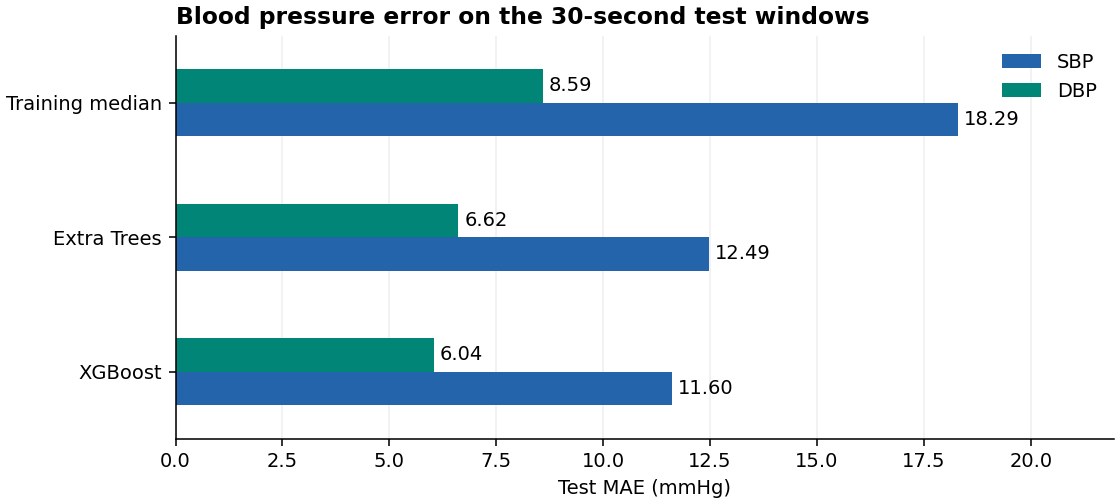

In [ ]:
# Show test MAE for the three approaches.

test_mae = scores[["Test SBP MAE", "Test DBP MAE"]].rename(
    columns={"Test SBP MAE": "SBP", "Test DBP MAE": "DBP"}
)
fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
test_mae.iloc[::-1].plot.barh(ax=ax, color=["#2364AA", "#008577"])
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set_xlim(0, test_mae.to_numpy().max() * 1.2)
ax.set_title("Blood pressure error on the 30-second test windows", loc="left", weight="bold")
ax.set_xlabel("Test MAE (mmHg)")
ax.set_ylabel("")
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()


## 5. See which pulse features XGBoost used most

XGBoost tracks how much each feature improves the decisions in its trees. Larger values mean
the model got more value from that feature during training. Related features can share credit.

,SBP,DBP
slope_positive_fraction,0.028,0.004
history8_ppg_std,0.022,0.007
history8_beat_shape_03,0.016,0.009
history8_beat_area_median,0.018,0.006
slope_q05,0.009,0.011
harmonic_2_power,0.014,0.006
optical_band_6,0.011,0.008
beat_area_median,0.005,0.014
slope_q95,0.007,0.012
history8_pulse_width_s,0.011,0.007


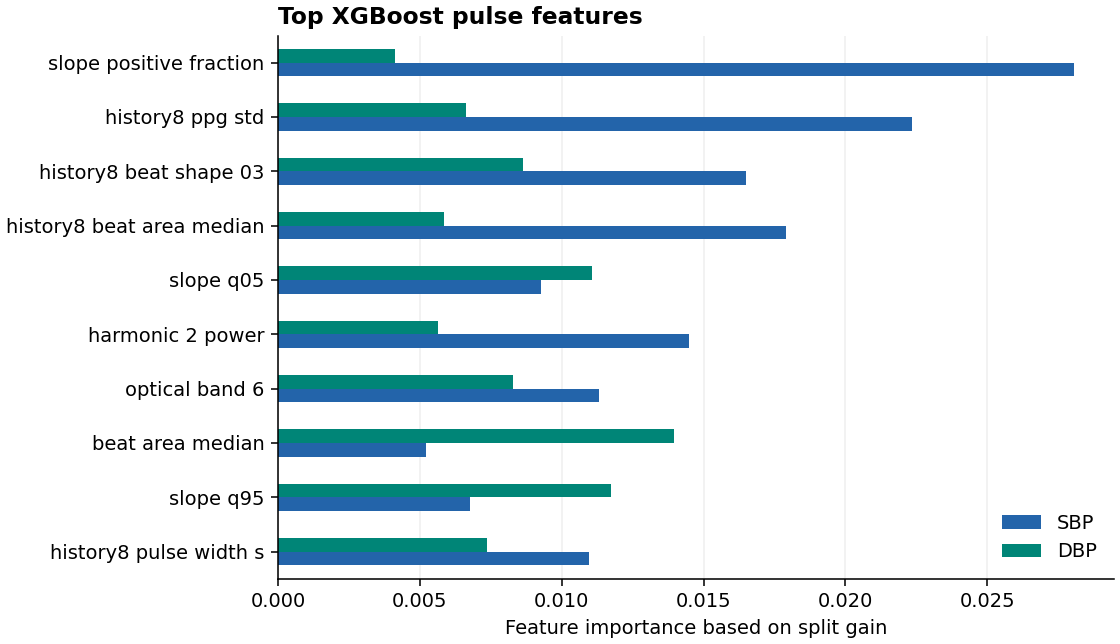

In [ ]:
# Show the ten most useful inputs across the two XGBoost regressors.

top = importance.loc[importance.mean(axis=1).nlargest(10).index]
display(top.round(3))
fig, ax = plt.subplots(figsize=(8, 4.6), layout="constrained")
top.rename(index=lambda name: name.replace("_", " ")).iloc[::-1].plot.barh(
    ax=ax, color=["#2364AA", "#008577"]
)
ax.set_title("Top XGBoost pulse features", loc="left", weight="bold")
ax.set_xlabel("Feature importance based on split gain")
ax.set_ylabel("")
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()
